# Comparison of Operator Surrogates

This notebook compares spectral and neural operator surrogates for the parametric diffusion problem.

In [1]:
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt
import time
plt.rcParams.update({'font.size': 12})

import jax
jax.config.update('jax_platform_name', 'cpu')
from smolyax import indices, nodes
from smolyax.interpolation import SmolyakBarycentricInterpolator

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

import error

from importer import import_notebook
import_notebook('0_Diffusion.ipynb', globals())        # provides: Grid, Diffusion
import_notebook('1_Representation.ipynb', globals())  # provides: Encoder, Decoder
import_notebook('3_PCANet.ipynb', globals())          # provides: FFN
import_notebook('4_FNO.ipynb', globals())             # provides: FNO

In [2]:
d_in   = 50      # input dimension
d_out  = 50      # PCA rank
n_pool = 2000    # shared data pool per decay (for PCA fitting and NN training)
n_test = 200     # test samples
decays = [1, 2, 3]
grid   = Grid(128)
rng    = np.random.default_rng(0)
torch.manual_seed(0)

# PCA-Net parameters
layers       = [64, 64]
n_epochs  = 200
n_trains_nn  = [100, 200, 500, 1000, 2000]

# FNO parameters
d_hidden     = 16
n_modes      = 16
n_layers_fno = 2
n_trains_fno = [100, 200, 500, 1000]   # fewer sizes to limit runtime

# Interpolation: target number of Leja nodes
n_targets_interp = np.unique(np.round(np.geomspace(20, 2000, 8)).astype(int))

## 1. Experiments

For each surrogate method and smoothness level $\alpha \in \{1, 2, 3\}$ we compare:
- **Accuracy**: relative $L^2$ error of the operator surrogate on a test data set
- **Number of PDE solves**: number of operator evaluations (i.e. numerical PDE solves) used to set up the surrogate
- **Training time**: setup/training time (excluding the time taken to evaluate the operator/PDE)
- **Evaluation time**: Evaluation time of the surrogate per sample

**Note:** Running 'Interpolation' and 'PCA-Net' takes about 3 minutes. Including 'FNO' leads to 10-15 minutes additional runtime.

In [3]:
surrogates = ['Interpolation', 'PCA-Net', 'FNO']
results    = {}  # (decay, method) -> {'n', 'err', 't_train', 't_eval'}

t0_total = time.perf_counter()
for decay in decays:
    print(f'\n=== alpha = {decay} ===')

    # --- shared data pool ---
    xb_pool = rng.uniform(-1., 1., (n_pool, d_in))
    t0     = time.perf_counter()
    x_pool = np.array([Encoder(parameter=xb, decay=decay)(grid.nodes_bd) for xb in xb_pool])
    y_pool = np.array([Diffusion(coefficient=Encoder(parameter=xb, decay=decay))(grid) for xb in xb_pool])
    t_pool = time.perf_counter() - t0

    decoder = Decoder(rank=d_out, samples=y_pool.T)
    yb_pool = decoder.analyse(y_pool)   # PCA coefficients, shape (n_pool, d_out)

    # --- test data ---
    xb_test = rng.uniform(-1., 1., (n_test, d_in))
    y_test = np.array([Diffusion(coefficient=Encoder(parameter=xb, decay=decay))(grid) for xb in xb_test])
    x_test = np.array([Encoder(parameter=xb, decay=decay)(grid.nodes_bd) for xb in xb_test])

    # ==========================================================
    # Smolyak Interpolation
    # ==========================================================
    if 'Interpolation' in surrogates:
        print('  [Interpolation]')
    
        node_gen = nodes.Leja(dim=d_in)
        k        = [decay * np.log(i + 2) for i in range(d_in)]
    
        def target(xb, _decoder=decoder, _decay=decay):
            return _decoder.analyse(Diffusion(coefficient=Encoder(parameter=np.array(xb), decay=_decay))(grid))
    
        # Pre-evaluate target at all nodes up to the maximum level (PDE solves, not timed)
        t_max   = indices.find_approximate_threshold(k, int(n_targets_interp[-1]), node_gen.is_nested)
        ip      = SmolyakBarycentricInterpolator(node_gen=node_gen, k=k, d_out=d_out, t=t_max)
        f_evals = ip.set_f(f=target)
    
        key = (decay, 'Interpolation')
        results[key] = {'n': [], 'err': [], 't_train': [], 't_eval': []}
    
        for n_target in n_targets_interp:
            t_      = indices.find_approximate_threshold(k, int(n_target), node_gen.is_nested)
    
            # Setup (timed): construct interpolant and trigger JIT compilation
            t0 = time.perf_counter()
            ip = SmolyakBarycentricInterpolator(node_gen=node_gen, k=k, d_out=d_out, t=t_, n_inputs=n_test)
            ip.set_f(f=target, f_evals=f_evals)  # reuse pre-computed evaluations
            results[key]['t_train'].append(time.perf_counter() - t0)
            results[key]['n'].append(ip.n_f_evals)
    
            # Evaluation time (depends on n)
            yb_pred = np.array(ip(xb_test))
            t0 = time.perf_counter()
            for _ in range(20): ip(xb_test)
            results[key]['t_eval'].append((time.perf_counter() - t0) / 20 / n_test)
    
            # Error
            y_pred = decoder.synthesise(yb_pred)
            results[key]['err'].append(error.l2_rel(y_test, y_pred))
            print(f'    n={results[key]["n"][-1]:5d}  err={results[key]["err"][-1]:.2e}  t={results[key]["t_train"][-1]:.2f}s')

    # ==========================================================
    # PCA-Net
    # ==========================================================
    
    if 'PCA-Net' in surrogates:
        print('  [PCA-Net]')
    
        key = (decay, 'PCA-Net')
        results[key] = {'n': [], 'err': [], 't_train': [], 't_eval': []}
    
        for n_train in n_trains_nn:
            t0  = time.perf_counter()
            net = FFN(d_in, d_out, layers)
            net.train({'x': xb_pool[:n_train], 'y': yb_pool[:n_train]}, None, n_epochs=n_epochs, verbose=False)
            results[key]['t_train'].append(time.perf_counter() - t0)
    
            y_pred = decoder.synthesise(net.forward(xb_test))
            results[key]['n'].append(n_train)
            results[key]['err'].append(error.l2_rel(y_test, y_pred))

            t0 = time.perf_counter()
            for _ in range(200): net.forward(xb_test)
            results[key]['t_eval'].append((time.perf_counter() - t0) / 200 / n_test)
            print(f'    n={n_train:5d}  err={results[key]["err"][-1]:.2e}  t={results[key]["t_train"][-1]:.1f}s')

    # ==========================================================
    # FNO
    # ==========================================================
    if 'FNO' in surrogates:
        print('  [FNO]')

        key = (decay, 'FNO')
        results[key] = {'n': [], 'err': [], 't_train': [], 't_eval': []}

        for n_train in n_trains_fno:
            t0  = time.perf_counter()
            fno = FNO(d_hidden=d_hidden, n_modes=n_modes, n_layers=n_layers_fno)
            fno.train({'x': x_pool[:n_train], 'y': y_pool[:n_train]}, None, n_epochs=n_epochs, verbose=False)
            results[key]['t_train'].append(time.perf_counter() - t0)

            y_pred = fno.forward(x_test)
            results[key]['n'].append(n_train)
            results[key]['err'].append(error.l2_rel(y_test, y_pred))

            t0 = time.perf_counter()
            for _ in range(200): fno.forward(x_test)
            results[key]['t_eval'].append((time.perf_counter() - t0) / 200 / n_test)
            print(f'    n={n_train:5d}  err={results[key]["err"][-1]:.2e}  t={results[key]["t_train"][-1]:.1f}s')

print(f'\nAll experiments done in {time.perf_counter() - t0_total:.0f}s.')


=== alpha = 1 ===
  [Interpolation]
    n=   17  err=7.96e-02  t=0.73s
    n=   41  err=5.61e-02  t=0.24s
    n=   78  err=4.73e-02  t=0.38s
    n=  143  err=3.48e-02  t=0.38s
    n=  295  err=2.48e-02  t=0.46s
    n=  537  err=1.65e-02  t=0.56s
    n= 1037  err=1.12e-02  t=0.64s
    n= 1984  err=7.59e-03  t=0.66s
  [PCA-Net]
    n=  100  err=1.62e-01  t=1.2s
    n=  200  err=1.06e-01  t=7.7s
    n=  500  err=5.19e-02  t=17.5s
    n= 1000  err=2.33e-02  t=11.9s
    n= 2000  err=1.24e-02  t=9.3s
  [FNO]
    n=  100  err=1.06e-01  t=13.2s
    n=  200  err=5.11e-02  t=24.8s
    n=  500  err=3.85e-02  t=53.3s
    n= 1000  err=2.59e-02  t=105.4s

=== alpha = 2 ===
  [Interpolation]
    n=   21  err=1.27e-02  t=0.39s
    n=   37  err=4.97e-03  t=0.20s
    n=   78  err=2.84e-03  t=0.30s
    n=  143  err=1.36e-03  t=0.35s
    n=  295  err=6.11e-04  t=0.35s
    n=  537  err=1.73e-04  t=0.37s
    n= 1037  err=8.65e-05  t=0.43s
    n= 1984  err=5.68e-05  t=0.57s
  [PCA-Net]
    n=  100  err=1.32

## 2. Results

### 2.1. Accuracy vs Training Data Volume

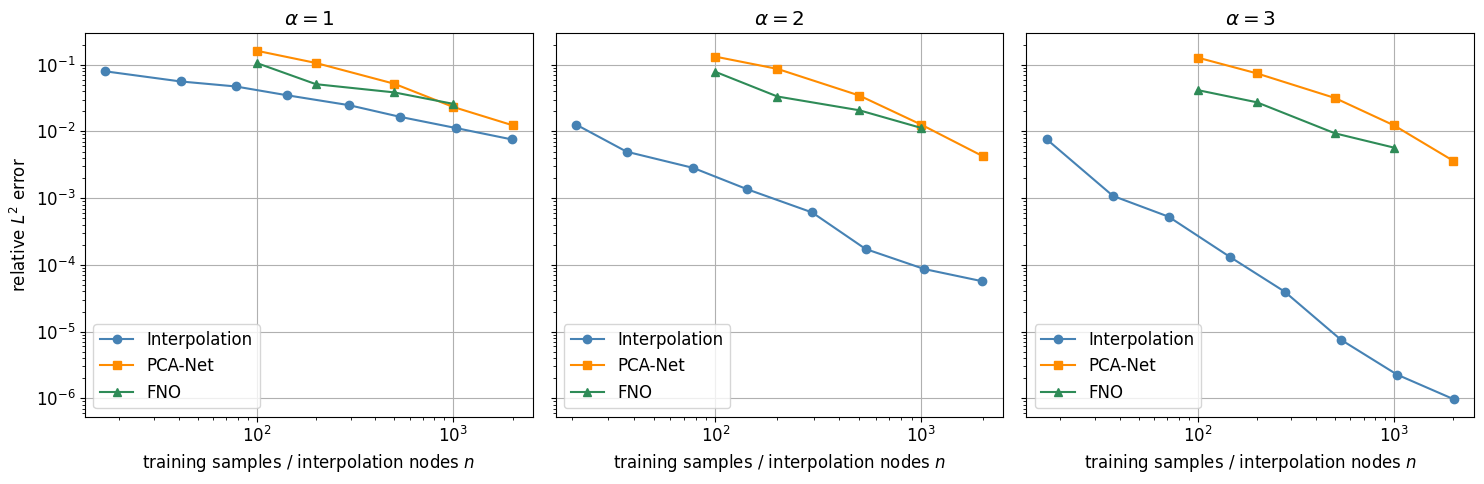

In [4]:
colors  = {'Interpolation': 'steelblue', 'PCA-Net': 'darkorange', 'FNO': 'seagreen'}
markers = {'Interpolation': 'o',         'PCA-Net': 's',          'FNO': '^'}

fig, axs = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

for ax, decay in zip(axs, decays):
    for method in surrogates:
        r = results[(decay, method)]
        ax.loglog(r['n'], r['err'], marker=markers[method], color=colors[method], label=method)
    ax.set_xlabel('training samples / interpolation nodes $n$')
    ax.set_title(rf'$\alpha = {decay}$')
    ax.legend(); ax.grid()

axs[0].set_ylabel('relative $L^2$ error')
plt.tight_layout()
plt.show()

### 2.2. Accuracy vs Training Time

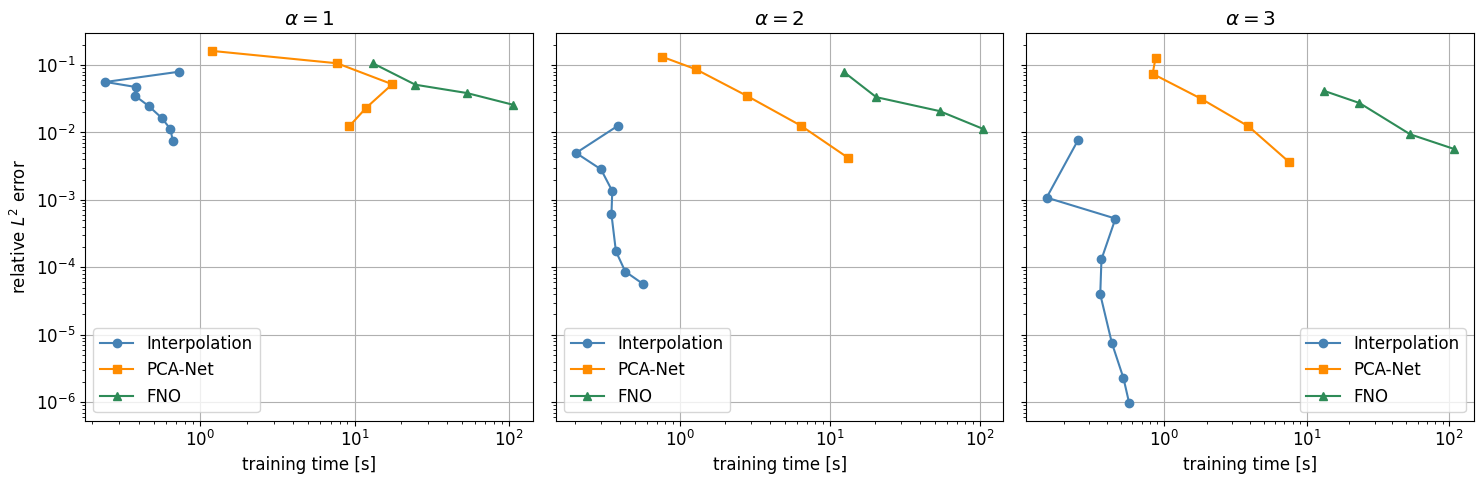

In [5]:
fig, axs = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

for ax, decay in zip(axs, decays):
    for method in surrogates:
        r = results[(decay, method)]
        ax.loglog(r['t_train'], r['err'], marker=markers[method], color=colors[method], label=method)
    ax.set_xlabel('training time [s]')
    ax.set_title(rf'$\alpha = {decay}$')
    ax.legend(); ax.grid()

axs[0].set_ylabel('relative $L^2$ error')
plt.tight_layout()
plt.show()

### 2.3. Accuracy vs Evaluation Time

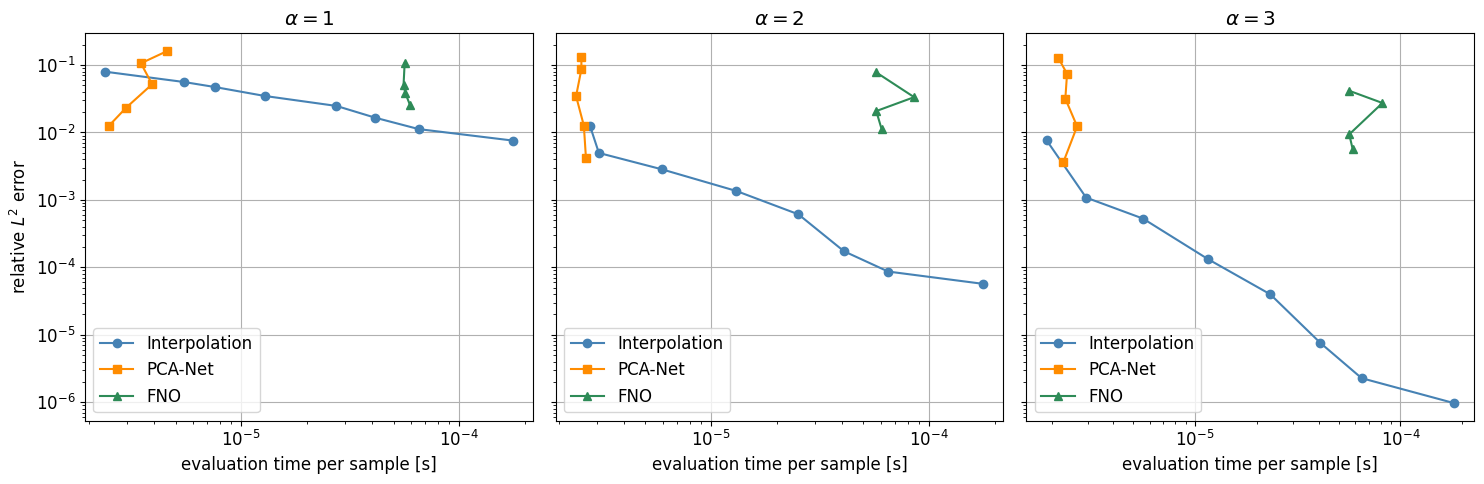

In [6]:
fig, axs = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

for ax, decay in zip(axs, decays):
    for method in surrogates:
        r = results[(decay, method)]
        ax.loglog(r['t_eval'], r['err'], marker=markers[method], color=colors[method], label=method)
    ax.set_xlabel('evaluation time per sample [s]')
    ax.set_title(rf'$\alpha = {decay}$')
    ax.legend(); ax.grid()

axs[0].set_ylabel('relative $L^2$ error')
plt.tight_layout()
plt.show()

## 3. Discussion

#### Observations
* All three methods improve in accuracy as the smoothness parameter $\alpha$ increases. Sparse-grid interpolation exploits this the most: its convergence rate improves noticeably with $\alpha$, reaching relative errors of $10^{-6}$ for $\alpha = 3$ while neural operators do not yet reach $10^{-3}$. 
* Neural operators require iterative gradient descent for training. This is more expensive for FNO than for PCA-Net, since it operates directly on full physical fields rather than a compressed PCA representation, and layer evaluation includes a Fourier transform. Sparse-grid interpolation only needs to assemble the interpolant from pre-computed PDE evaluations, so setup cost is negligible.
* Once trained, a neural operator evaluates in a fixed time determined solely by its architecture, regardless of how many training samples were used. This is reflected in the roughly vertical curves in the evaluation time plot: adding more training data improves accuracy (moving points downwards) without affecting the per-sample evaluation cost. FNO is again more expensive here, due to Fourier transforms in the layers.
* Sparse-grid interpolation evaluation scales with the number of nodes $n$, so higher accuracy directly implies a higher per-query cost.

#### Limitations
* The accuracy of operator surrogates can be sensitive to hyperparameter choices. For neural networks, these include learning rate, architecture width, and number of training epochs. The polynomial operator surrogate relies on choices of interpolation nodes and multi-index sets. We therefore emphasize that the results shown here may vary with different configurations.
* Runtime measurements are highly sensitive to implementation details and hardware - timings depend, for example, on JIT compilation, vectorization, and whether a CPU or GPU is used.